# Картинка без сюрпризов: один входной формат

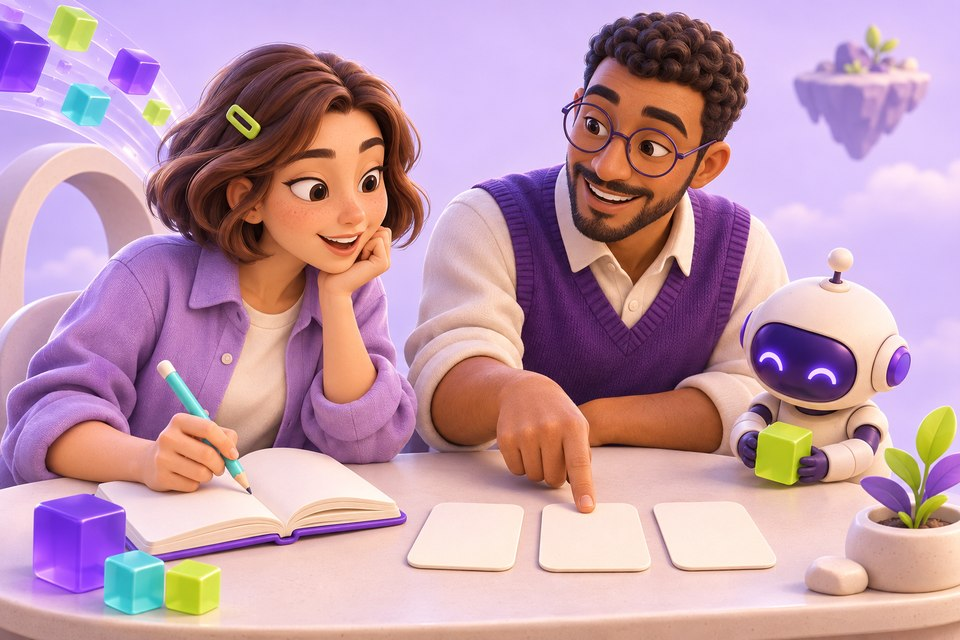

**Подготовим яркость одинаково для обучения и ответа.**

**Твой результат:** Проверить тип, диапазон и форму изображения.

**Что разбираем:** Входной контракт на NumPy по мотивам эксперимента EfficientNetB7. Правила реальной EfficientNet здесь не подменяются этим учебным контрактом. Медицинский эксперимент сохранён в архиве, но здесь не воспроизводится.

**Данные:** Явно синтетические неклинические учебные массивы и геометрические фигуры, созданные в коде. Это не снимки пациентов.

**Перед началом:**

- Запускать ячейки сверху вниз
- Знать, что изображение можно представить массивом

**Рядом с тобой:** Мира — ученица, Данил — человек-ментор, Пикс — бот-помощник. Это вымышленные персонажи: их реплики объясняют шаги и не проверяют код автоматически.

## Три шага

1. Создадим пиксельную открытку
2. Подготовим одним способом
3. Поймаем повторную обработку

Затем — твой небольшой эксперимент. Проходи ячейки сверху вниз.

## Подготовь рабочее место

Запускай код сверху вниз: сначала эту подготовку, затем три шага. Проверки `assert` останавливают выполнение, если результат не совпал с условием.

Библиотеки для урока: **numpy, matplotlib**.

In [1]:
%matplotlib inline
import matplotlib as mpl
mpl.rcParams.update({
    'figure.figsize': (7, 3.5), 'figure.dpi': 100,
    'figure.facecolor': '#fffdf8', 'axes.facecolor': '#fffdf8',
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.titlesize': 12, 'axes.labelcolor': '#302c3f',
    'text.color': '#302c3f', 'savefig.bbox': 'tight',
})
import numpy as np
import matplotlib.pyplot as plt


<a id="step-1"></a>

## 1. Создадим пиксельную открытку

Серый квадрат хранит числа от 0 до 255. Сначала явно объявим этот формат, чтобы не делить уже нормализованные числа повторно.

In [2]:
pixels = np.zeros((12, 12), dtype=np.uint8)
pixels[3:9, 3:9] = 180
pixels[5:7, 5:7] = 255
assert pixels.dtype == np.uint8 and pixels.shape == (12, 12)
print('Вход:', pixels.dtype, 'диапазон:', pixels.min(), pixels.max())


Вход: uint8 диапазон: 0 255


**Что проверить:** Тип uint8 и диапазон исходных пикселей.

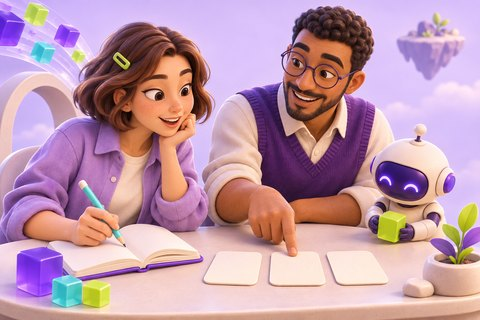

> **Мира:** Почему нельзя догадаться о формате по максимальному числу?

> **Данил:** Очень тёмное изображение тоже может иметь маленький максимум. Надёжнее договориться о типе заранее.

> **Пикс:** Контракт сейчас требует uint8, а не произвольные числа.

<a id="step-2"></a>

## 2. Подготовим одним способом

Функция проверяет вход и возвращает float32 в диапазоне 0–1. Ту же функцию используем для обоих путей.

In [3]:
def prepare(raw):
    raw = np.asarray(raw)
    if raw.dtype != np.uint8 or raw.shape != (12, 12):
        raise ValueError('Нужен массив uint8 размером 12×12')
    return raw.astype(np.float32)[None, :, :, None] / 255.0
training_input = prepare(pixels)
serving_input = prepare(pixels.copy())
assert training_input.shape == (1, 12, 12, 1)
assert np.array_equal(training_input, serving_input)
assert 0 <= training_input.min() <= training_input.max() <= 1
print('После подготовки:', training_input.shape, training_input.dtype)


После подготовки: (1, 12, 12, 1) float32


**Что проверить:** Одинаковые массивы на двух путях.

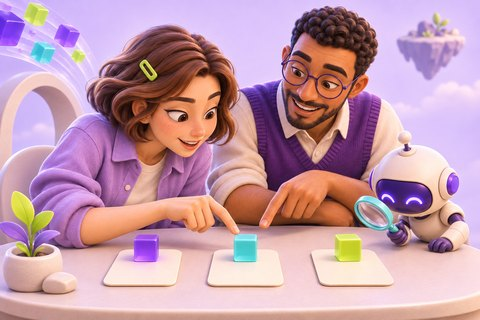

> **Мира:** В приложении можно написать похожую функцию заново?

> **Данил:** Лучше использовать одну и ту же. Маленькая разница масштаба меняет вход модели.

> **Пикс:** Сравнение проверяет все элементы, не только форму.

<a id="step-3"></a>

## 3. Поймаем повторную обработку

Попробуем передать уже подготовленный массив. Понятная ошибка защищает от скрытого повторного деления.

Неверный формат отклонён: Нужен массив uint8 размером 12×12


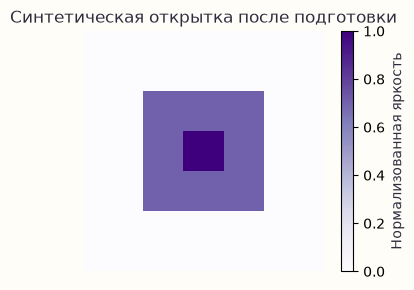

In [4]:
try:
    prepare(training_input[0, :, :, 0])
except ValueError as error:
    print('Неверный формат отклонён:', error)
else:
    raise AssertionError('Повторная нормализация должна быть отклонена')
plt.figure(figsize=(4, 3))
plt.imshow(serving_input[0, :, :, 0], cmap='Purples', vmin=0, vmax=1)
plt.title('Синтетическая открытка после подготовки')
plt.colorbar(label='Нормализованная яркость')
plt.axis('off')
plt.tight_layout()
plt.show()


**Что проверить:** Вместо молчаливого изменения масштаба получаем отказ.

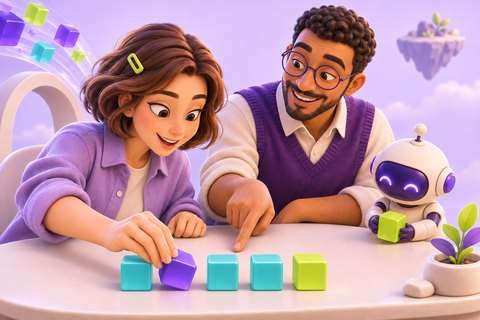

> **Мира:** Значит эта функция подходит любой сети?

> **Данил:** Нет. Здесь свой учебный формат. Для настоящей архитектуры проверяют её конкретный входной контракт.

> **Пикс:** Запомни принцип одинаковой подготовки, а не универсальность деления на 255.

<a id="your-experiment"></a>

## Попробуй сам

Поменяй яркость квадрата с 180 на 90.

**Где изменить:** pixels[3:9,3:9] в шаге 1.

**Как проверить:** Диапазон остаётся 0–1, рисунок темнеет, оба пути дают одинаковый массив.

## Что теперь умеешь

- Тип и форма — часть договора о данных.
- Подготовка должна совпадать на всех путях.

## Границы этого примера

- Упражнение не предназначено для диагностики и не оценивает медицинское качество.
- Реализован только названный учебный компонент; полная архивная нейросеть не загружается и не обучается.
- Ссылка на медицинский набор сохранена только как атрибуция архивного опыта; короткий урок его не загружает и не использует.

## Продолжить глубже

[Полная исходная работа в неизменяемом архиве](<https://github.com/safal207/students/blob/2e46691c24aabcb6e71852e07254a0965fc3a59b/medicina/%22%D0%98%D1%81%D0%BF%D0%BE%D0%BB%D1%8C%D0%B7%D1%83%D0%B5%D0%BC_%D0%BC%D0%BE%D0%B4%D0%B5%D0%BB%D1%8C_EfficientNet_B7_%D0%B4%D0%BB%D1%8F_%D1%80%D0%B0%D1%81%D0%BF%D0%BE%D0%B7%D0%BD%D0%B0%D0%B2%D0%B0%D0%BD%D0%B8%D1%8F_tuberculosis%22.ipynb>). Она сохраняет большой эксперимент и его авторские материалы; её требования могут отличаться от этого короткого урока.

**Источники исходной работы:**

- [Источник 1](<https://colab.research.google.com/github/safal207/hello-world/blob/master/%22%D0%98%D1%81%D0%BF%D0%BE%D0%BB%D1%8C%D0%B7%D1%83%D0%B5%D0%BC_%D0%BC%D0%BE%D0%B4%D0%B5%D0%BB%D1%8C_EfficientNet_B7_%D0%B4%D0%BB%D1%8F_%D1%80%D0%B0%D1%81%D0%BF%D0%BE%D0%B7%D0%BD%D0%B0%D0%B2%D0%B0%D0%BD%D0%B8%D1%8F_tuberculosis%22.ipynb>)
- [Источник 2](<https://www.kaggle.com/kmader/pulmonary-chest-xray-abnormalities/home>)
- [Источник 3](<https://www.dropbox.com/s/f64cvlhm0gp80v5/tuberculosis.zip?dl=1>)

<details>
<summary>Что исправлено и упрощено в уроке</summary>

**Ошибка · исходная ячейка 36 (от 0).** Подпись обучения называет другую архитектуру. → Новый заголовок точно называет выполняемую подготовку, не другую модель.

Проверка: В уроке нет утверждения о запуске Inception или EfficientNet.

Фрагмент исходника: <code>Обучаем ... InceptionV3 при EfficientNetB7</code>

---

**Ограничение исходного примера · исходная ячейка 39 (от 0).** test_generator участвует в выборе по validation; независимый тест не выделен. → Урок не заявляет тестовую точность; проверяет только детерминированный контракт входа.

Проверка: np.array_equal(training_input, serving_input)

Фрагмент исходника: <code>validation_data=test_generator</code>

</details>